# Measure the flop rate as processes share a node

You'll read the flop counters of amg's solve on one node of each system, and see how the flop rate of one process and of the whole node change as more processes share the node.
It takes about 10 minutes of your time on a compute node.

## Before you start

This notebook and the next six read the full sweep, so start the Jupyter kernel inside an allocation, such as one from `flux alloc -N 1 -q pdebug -t 60m`.

Then read the runs and open the full sweep, with the index of [Read the full sweep in a Flux job](../tutorials/04-read-the-full-sweep-in-a-flux-job.md).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

## 1. Pick the runs

Take amg with the input `p1_n64x64x32` on one node.
Each process gets the same problem size, so with no contention the time and the flop rate of a process would not change with the number of processes.

In [3]:
one_node = runs[
    (runs["app"] == "amg") & (runs["unique_input"] == "p1_n64x64x32") & (runs["nodes"] == 1)
]
display(one_node.groupby(["system", "ppn"]).size().pivot_table(index="system", columns="ppn", values="size"))

,system,1,2,4,8,16,32,64
0,matrix,2,2,2,2,2,2,2
1,tioga,8,8,8,8,8,8,None
2,tuolumne,9,9,9,9,9,9,9


There is one run for each counter set of a setting: 2 sets on matrix, 8 on tioga and 9 on tuolumne.

## 2. Read the flops and the time of the solve

matrix counts double-precision operations in `PAPI_DP_OPS`.
tioga and tuolumne count floating-point operations in `PAPI_FP_OPS`.
Only the runs of the counter set that holds the counter have a value.

In [4]:
SOLVE = "main;hypre_PCGSolve"
flops = tv.filter(
    (col("gtype") == "counter")
    & (col("path") == SOLVE)
    & col("metric").isin(["PAPI_DP_OPS", "PAPI_FP_OPS"])
    & col("run").isin(one_node["run"].to_pandas().tolist())
).collect()
time = tv.filter((col("gtype") == "func") & (col("path") == SOLVE)).collect()
solve = flops.merge(time[["run", "dur.sum"]], on="run").merge(one_node[["run", "system", "ppn"]], on="run")
matrix = solve["system"] == "matrix"
solve = solve[(matrix & (solve["metric"] == "PAPI_DP_OPS")) | (~matrix & (solve["metric"] == "PAPI_FP_OPS"))]
print(solve.shape)

(20, 21)


`v.sum` is the counter summed over the processes and over the calls, and `dur.sum` the time summed the same way.
Their ratio is the flop rate of one process.

In [5]:
solve = solve.assign(per_process=solve["v.sum"] / (solve["dur.sum"] / 1e6) / 1e9)
solve = solve.assign(per_node=solve["per_process"] * solve["ppn"])
rate = solve[["system", "ppn", "per_process", "per_node"]].groupby(["system", "ppn"]).median()
display(rate)

,system,ppn,per_process,per_node
0,matrix,1,1.919336,1.919336
1,matrix,2,1.820087,3.640174
2,matrix,4,1.443278,5.773114
3,matrix,8,1.230181,9.841447
4,matrix,16,0.797730,12.763686
5,matrix,32,0.485418,15.533382
6,matrix,64,0.486700,31.148813
7,tioga,1,2.443176,2.443176
8,tioga,2,2.162246,4.324492
9,tioga,4,1.196408,4.785631


## 3. Plot both rates

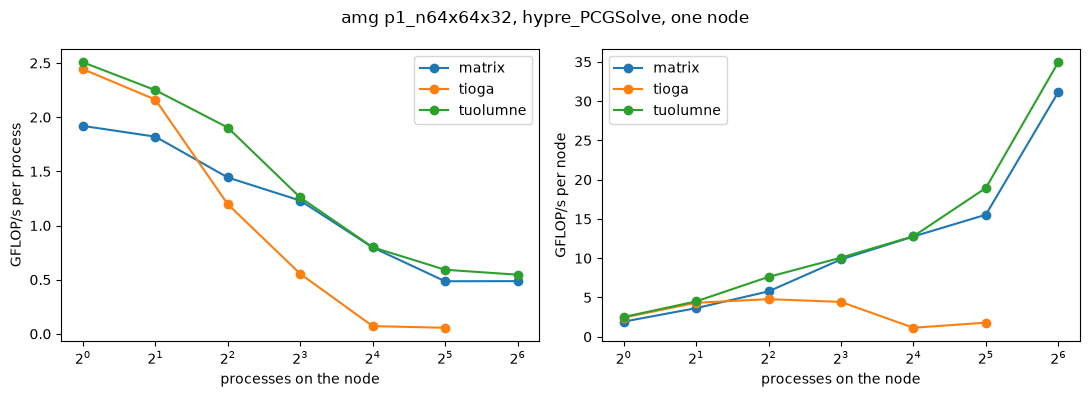

In [6]:
r = rate.to_pandas()
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for system, rows in r.groupby("system"):
    left.plot(rows["ppn"], rows["per_process"], marker="o", label=system)
    right.plot(rows["ppn"], rows["per_node"], marker="o", label=system)
for ax, what in [(left, "per process"), (right, "per node")]:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("processes on the node")
    ax.set_ylabel(f"GFLOP/s {what}")
    ax.legend()
fig.suptitle("amg p1_n64x64x32, hypre_PCGSolve, one node")
fig.tight_layout()
fig.savefig("../figures/flops-per-node.png", dpi=120)
plt.show()

On matrix one process runs the solve at 1.9 GFLOP/s, and with 32 processes each one gets 0.49 GFLOP/s.
The node total grows only from 1.9 to 15.5 GFLOP/s for 32 times the processes.
At 64 processes it doubles again, to 31 GFLOP/s, and the trace alone does not say why.
The processes compete for memory bandwidth, as [Build the call tree of one amg run](05-build-the-call-tree-of-one-run.ipynb) suggested for the matrix-vector product.
tuolumne behaves the same way.
On tioga the node total stops near 4.8 GFLOP/s at 4 processes and falls to about 1 GFLOP/s at 16, where the processes wait in MPI, as the next page shows.

## Limits

The counters are sampled per process and given to each call by its overlap in time, so every call inside one sample gets the rate of that sample.
A rate is reliable for a long phase such as the solve, not for one short call inside it.

## What you built

You turned the flop counters and the time of one phase into the flop rate of a process and of a node, for each system.

- Next: [Measure how much of main is MPI](07-mpi-share-of-main.ipynb)
- How counters are given to calls: [Build per-function distributions from genesis traces](https://dftracer.readthedocs.io/projects/utils/en/latest/guides/tools/genesis-gen-dist.html)